In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("Wine.csv")
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [3]:
X = df.drop("Customer_Segment", axis = 1)
y = df["Customer_Segment"]

In [24]:
y_binary = y.map({1: 'Red Wine', 2: 'White Wine', 3: 'White Wine'})

In [25]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [26]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [27]:
print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.2%}")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]:.2%}")
print(f"Total Variance Captured: {sum(pca.explained_variance_ratio_):.2%}")

Variance explained by PC1: 36.20%
Variance explained by PC2: 19.21%
Total Variance Captured: 55.41%


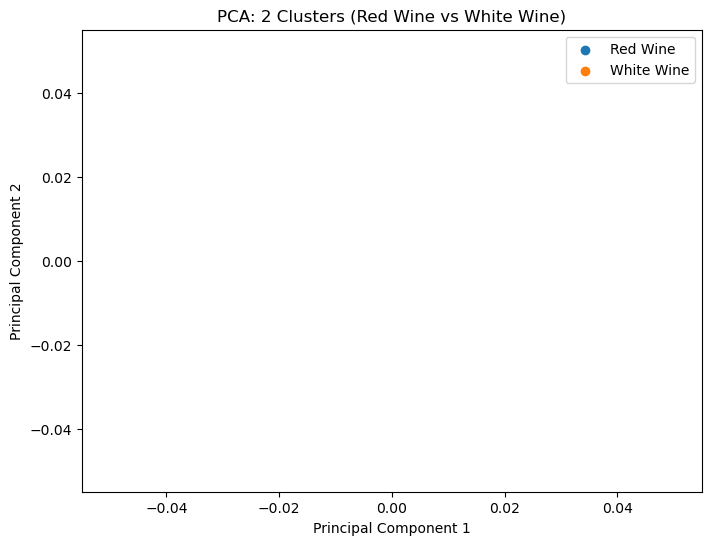

In [28]:
plt.figure(figsize=(8,6))
for wine_type in ['Red Wine', 'White Wine']:
    plt.scatter(
        X_pca[y_binary == wine_type, 0],
        X_pca[y_binary == wine_type, 1],
        label = wine_type,
    )
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: 2 Clusters (Red Wine vs White Wine)')
plt.legend()
plt.show()

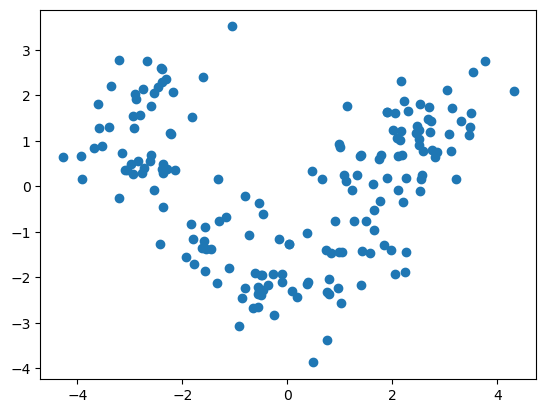

In [22]:
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.show()